# Part A — Insurance Claim Prediction (Machine Learning, 30%)

**Business context:** an insurance company wants to predict whether a customer/policy is likely to result in an insurance claim.

**Goal:** build and evaluate a **classification model** that predicts `insuranceclaim` (1 = claim, 0 = no claim).

Dataset: `data/insurance.csv` — columns `age, sex, bmi, children, smoker, region, charges, insuranceclaim`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

import warnings
# numpy on macOS (Accelerate BLAS) emits spurious "divide by zero in matmul" warnings from scikit-learn; results are unaffected
warnings.filterwarnings("ignore", category=RuntimeWarning, message=".*encountered in matmul")

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Task 1 — Dataset Understanding

In [2]:
df = pd.read_csv("data/insurance.csv")

print("1. First 5 records")
display(df.head())

1. First 5 records


,age,sex,bmi,children,smoker,region,charges,insuranceclaim
0,19,0,27.900,0,1,3,16884.92400,1
1,18,1,33.770,1,0,2,1725.55230,1
2,28,1,33.000,3,0,2,4449.46200,0
3,33,1,22.705,0,0,1,21984.47061,0
4,32,1,28.880,0,0,1,3866.85520,1


In [3]:
print("2. Last 5 records")
display(df.tail())

2. Last 5 records


,age,sex,bmi,children,smoker,region,charges,insuranceclaim
1333,50,1,30.97,3,0,1,10600.5483,0
1334,18,0,31.92,0,0,0,2205.9808,1
1335,18,0,36.85,0,0,2,1629.8335,1
1336,21,0,25.80,0,0,3,2007.9450,0
1337,61,0,29.07,0,1,1,29141.3603,1


In [4]:
rows, cols = df.shape
print(f"3. Rows: {rows}, Columns: {cols}")
print("4. Column names:", list(df.columns))

3. Rows: 1338, Columns: 8
4. Column names: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges', 'insuranceclaim']


In [5]:
print("5. Data types")
print(df.dtypes)

5. Data types
age                 int64
sex                 int64
bmi               float64
children            int64
smoker              int64
region              int64
charges           float64
insuranceclaim      int64
dtype: object


In [6]:
print("6. Missing values per column")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

6. Missing values per column
age               0
sex               0
bmi               0
children          0
smoker            0
region            0
charges           0
insuranceclaim    0
dtype: int64

Total missing values: 0
Duplicate rows: 1


In [7]:
# Unique values help decide whether a column is numerical or categorical
df.nunique()

age                 47
sex                  2
bmi                548
children             6
smoker               2
region               4
charges           1337
insuranceclaim       2
dtype: int64

In [8]:
# Target balance
counts = df["insuranceclaim"].value_counts()
pct = df["insuranceclaim"].value_counts(normalize=True).mul(100).round(2)
pd.DataFrame({"count": counts, "percent": pct})

,count,percent
insuranceclaim,,
1,783,58.52
0,555,41.48


### Answers — Task 1

**1. Numerical variables:** `age`, `bmi`, `children`, `charges` — these are measured quantities where arithmetic and order are meaningful (`children` is a discrete count).

**2. Categorical variables:** `sex`, `smoker`, `region` (and the target `insuranceclaim`).
They are already stored as integer codes in this file:
- `sex` (0/1) and `smoker` (0/1) are **binary** — the 0/1 code can be used as-is.
- `region` (0, 1, 2, 3) is **nominal** — the numbers are labels, not an order (region 3 is not "three times" region 1), so it must be one-hot encoded.

**3. Target variable:** `insuranceclaim` — 1 = the policy resulted in a claim, 0 = no claim. This is a binary classification problem.

**4. Is the target balanced?** Roughly 58.5% claims (783) vs 41.5% no-claims (555). It is **mildly imbalanced but not severely** — both classes are well represented, so standard classifiers work. We still use a **stratified** train/test split to keep this ratio in both sets, and we look at precision/recall/F1/ROC-AUC, not just accuracy.

**Data quality:** no missing values; there is 1 exact duplicate row, which we drop before splitting so the same record cannot appear in both train and test.

In [9]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1337, 8)


## Task 2 — Exploratory Data Analysis (Univariate)

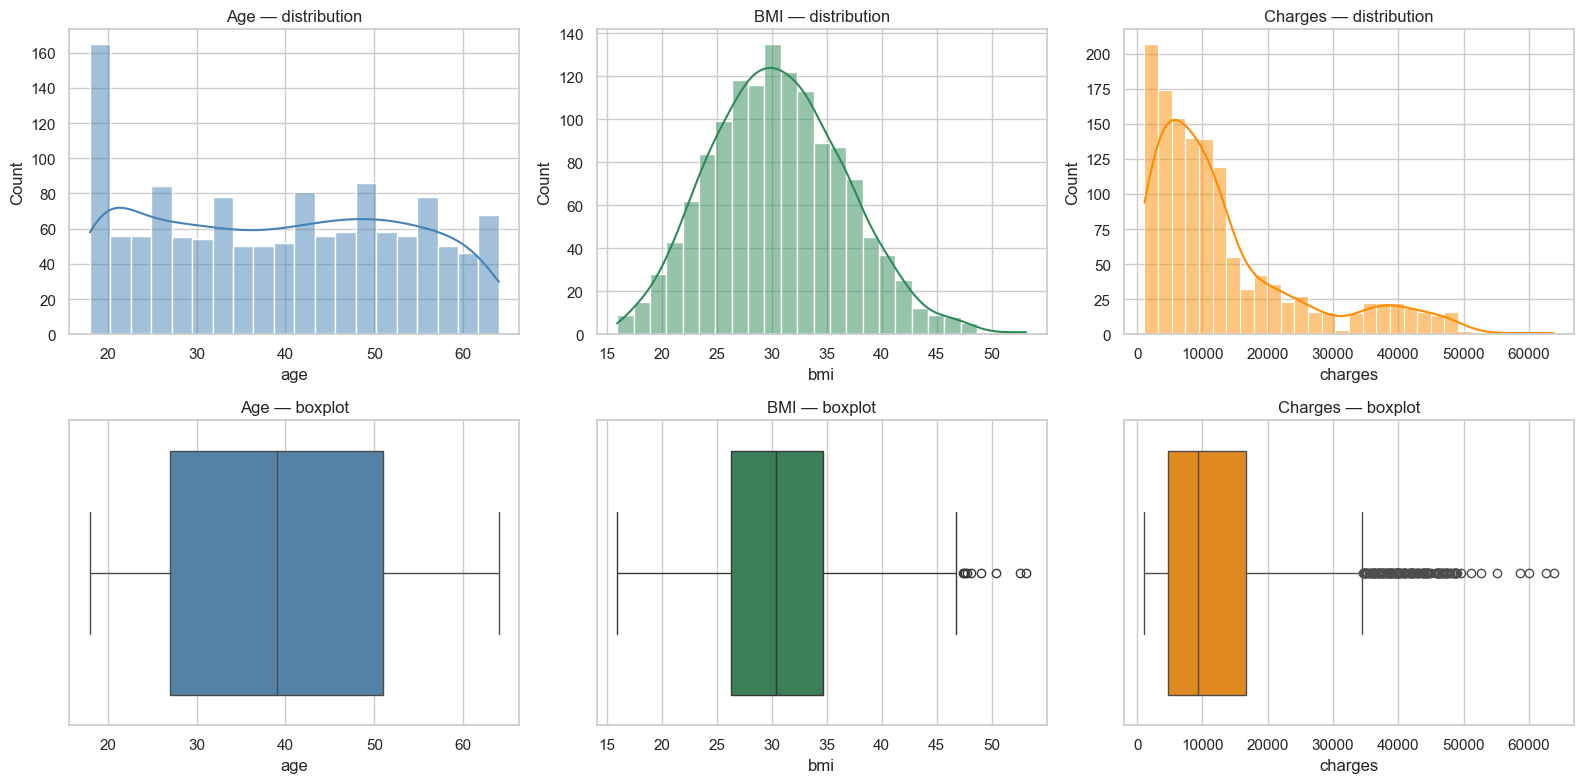

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

sns.histplot(df["age"], bins=20, kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Age — distribution")
sns.boxplot(x=df["age"], ax=axes[1, 0], color="steelblue")
axes[1, 0].set_title("Age — boxplot")

sns.histplot(df["bmi"], bins=25, kde=True, ax=axes[0, 1], color="seagreen")
axes[0, 1].set_title("BMI — distribution")
sns.boxplot(x=df["bmi"], ax=axes[1, 1], color="seagreen")
axes[1, 1].set_title("BMI — boxplot")

sns.histplot(df["charges"], bins=30, kde=True, ax=axes[0, 2], color="darkorange")
axes[0, 2].set_title("Charges — distribution")
sns.boxplot(x=df["charges"], ax=axes[1, 2], color="darkorange")
axes[1, 2].set_title("Charges — boxplot")

plt.tight_layout()
plt.show()

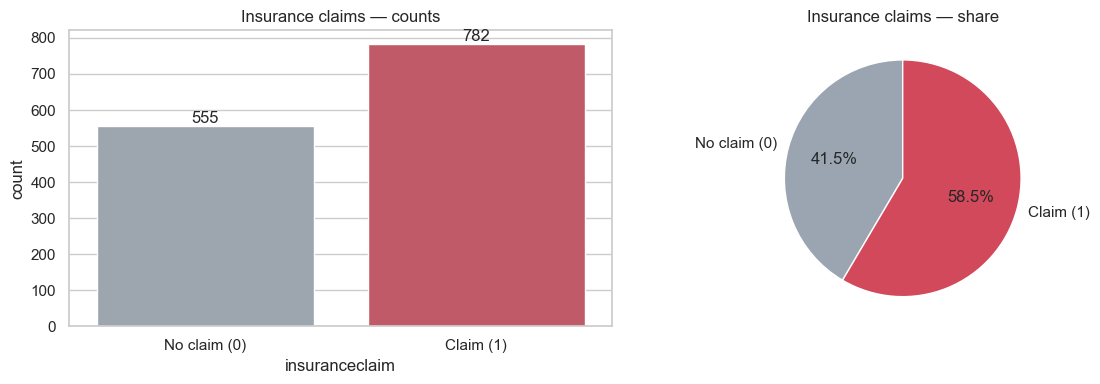

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = [0, 1]
sns.countplot(x="insuranceclaim", data=df, order=order, ax=ax[0], palette=["#9aa5b1", "#d1495b"], hue="insuranceclaim", legend=False)
ax[0].set_title("Insurance claims — counts")
ax[0].set_xticks([0, 1], ["No claim (0)", "Claim (1)"])
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

df["insuranceclaim"].value_counts().sort_index().plot.pie(
    ax=ax[1], labels=["No claim (0)", "Claim (1)"], autopct="%1.1f%%", colors=["#9aa5b1", "#d1495b"], startangle=90)
ax[1].set_ylabel("")
ax[1].set_title("Insurance claims — share")
plt.tight_layout()
plt.show()

In [12]:
df[["age", "bmi", "charges"]].describe().T.assign(skew=df[["age", "bmi", "charges"]].skew())

,count,mean,std,min,25%,50%,75%,max,skew
age,1337.0,39.222139,14.044333,18.0000,27.000,39.0000,51.00000,64.00000,0.054781
bmi,1337.0,30.663452,6.100468,15.9600,26.290,30.4000,34.70000,53.13000,0.283914
charges,1337.0,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801,1.515391


### EDA observations
- **Age:** spread fairly evenly between 18 and 64, with a spike at 18–19 (many young policyholders). No outliers.
- **BMI:** roughly normal (bell-shaped), centred around 30, with a few high outliers above ~47. Mean BMI ≈ 30.7, i.e. on average the population is at the overweight/obese boundary.
- **Charges:** strongly **right-skewed** — most policies cost under ~15,000, with a long tail up to ~64,000 (many outliers in the boxplot). Scaling is important for this feature in distance/gradient-based models.
- **Insurance claims:** 58.5% claim vs 41.5% no-claim — mildly imbalanced, handled with a stratified split and balanced metrics.

## Task 3 — Data Preprocessing

Approach (all leakage-safe):
1. Separate `X` (features) and `y` (target).
2. Split into train/test **first** (80/20, stratified on `y`).
3. Build a `ColumnTransformer` that
   - **scales** numerical features (`age, bmi, children, charges`) with `StandardScaler`,
   - **one-hot encodes** the nominal feature `region`,
   - passes the binary 0/1 features `sex` and `smoker` through unchanged.
4. Put the transformer and the model inside one `Pipeline`, so the scaler/encoder are **fitted only on the training data** and merely *applied* to the test data.

In [13]:
# 1. Separate independent variables and target
X = df.drop(columns=["insuranceclaim"])
y = df["insuranceclaim"]

numeric_features = ["age", "bmi", "children", "charges"]
nominal_features = ["region"]
binary_features = ["sex", "smoker"]

# 3. Train/test split (before any fitting -> no leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Claim rate train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (1069, 7)  Test: (268, 7)
Claim rate train: 0.585 | test: 0.586


In [14]:
# 2 & 4. Encoding + scaling, defined once and fitted only on training data inside the pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("region", OneHotEncoder(handle_unknown="ignore", drop="first"), nominal_features),
        ("bin", "passthrough", binary_features),
    ]
)

# Show what the model will actually see (fit on TRAIN only, then transform test)
preprocessor.fit(X_train)
feature_names = preprocessor.get_feature_names_out()
X_train_prepared = pd.DataFrame(preprocessor.transform(X_train), columns=feature_names, index=X_train.index)
X_test_prepared = pd.DataFrame(preprocessor.transform(X_test), columns=feature_names, index=X_test.index)
print("Features after preprocessing:", list(feature_names))
display(X_train_prepared.head())
print("Scaled train means (≈0):", X_train_prepared.filter(like="num__").mean().round(3).to_dict())
print("Scaled test means (not exactly 0 — scaler used TRAIN statistics):", X_test_prepared.filter(like="num__").mean().round(3).to_dict())

Features after preprocessing: ['num__age', 'num__bmi', 'num__children', 'num__charges', 'region__region_1', 'region__region_2', 'region__region_3', 'bin__sex', 'bin__smoker']


,num__age,num__bmi,num__children,num__charges,region__region_1,region__region_2,region__region_3,bin__sex,bin__smoker
1290,-1.438052,0.701262,-0.900799,1.836934,0.0,0.0,1.0,1.0,1.0
359,-1.509374,-1.630921,-0.900799,-0.968728,0.0,1.0,0.0,0.0,0.0
579,-1.010119,-1.188781,-0.900799,-0.833687,0.0,0.0,0.0,0.0,0.0
662,-1.509374,0.496307,-0.900799,-1.008515,0.0,1.0,0.0,1.0,0.0
1167,-0.510864,0.750847,0.759466,-0.710034,0.0,0.0,1.0,1.0,0.0


Scaled train means (≈0): {'num__age': -0.0, 'num__bmi': -0.0, 'num__children': -0.0, 'num__charges': 0.0}
Scaled test means (not exactly 0 — scaler used TRAIN statistics): {'num__age': 0.021, 'num__bmi': 0.005, 'num__children': 0.044, 'num__charges': 0.085}


### Question — Why learn preprocessing transformations from the training set only?

The test set stands in for **future, unseen data**. Any statistic used to transform the data — the mean and standard deviation for `StandardScaler`, the categories for `OneHotEncoder`, imputation values, etc. — is part of what the model "learns".

If we fit these on the **complete** dataset, information from the test rows (e.g. their influence on the mean/std of `charges`) leaks into the training process. This is **data leakage**:
- The evaluation becomes **optimistically biased** — the model has indirectly "seen" the test data, so the test score overstates real-world performance.
- In production we will never have future data when we fit the scaler, so fitting on everything does not reflect how the model will really be used.

The correct workflow is: split first → `fit` the transformers on the training data → `transform` both train and test with those same fitted parameters. Wrapping the preprocessing and model in a scikit-learn `Pipeline` enforces this automatically (including inside cross-validation). As the output above shows, the scaled training features have mean 0, while the test features do not — exactly because the test set was transformed using training statistics.

## Task 4 — Build the Machine Learning Model

**Main model: Logistic Regression** — a standard, interpretable baseline for binary classification that outputs calibrated-ish probabilities and whose coefficients can be explained to the business.
A **Random Forest** is also trained as a comparison model to check whether non-linear relationships add value.

In [15]:
# 1. Train the model
log_reg = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
log_reg.fit(X_train, y_train)

# 2. Predictions
y_pred_lr = log_reg.predict(X_test)

# 3. Prediction probabilities (probability of class 1 = claim)
y_proba_lr = log_reg.predict_proba(X_test)[:, 1]

pd.DataFrame({
    "actual": y_test.values[:10],
    "predicted": y_pred_lr[:10],
    "P(claim)": y_proba_lr[:10].round(3),
}, index=X_test.index[:10])

,actual,predicted,P(claim)
19,1,1,0.999
201,1,1,0.630
222,0,0,0.053
750,1,1,0.606
543,1,1,1.000
536,0,0,0.288
1020,1,1,0.725
816,0,0,0.178
562,1,1,0.765
1114,1,1,0.714


In [16]:
def evaluate(name, y_true, y_pred, y_proba):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba),
    }

# 4. Evaluate
print(classification_report(y_test, y_pred_lr, target_names=["No claim", "Claim"]))
results = [evaluate("Logistic Regression", y_test, y_pred_lr, y_proba_lr)]
pd.DataFrame(results).set_index("model").round(3)

              precision    recall  f1-score   support

    No claim       0.85      0.81      0.83       111
       Claim       0.87      0.90      0.88       157

    accuracy                           0.86       268
   macro avg       0.86      0.85      0.86       268
weighted avg       0.86      0.86      0.86       268



,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.862,0.87,0.898,0.884,0.904


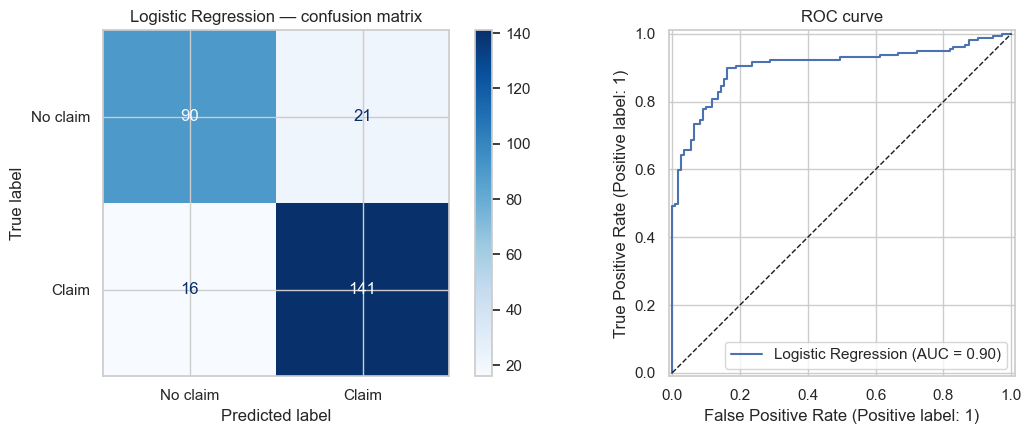

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, display_labels=["No claim", "Claim"], cmap="Blues", ax=ax[0])
ax[0].set_title("Logistic Regression — confusion matrix")
RocCurveDisplay.from_predictions(y_test, y_proba_lr, name="Logistic Regression", ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_title("ROC curve")
plt.tight_layout()
plt.show()

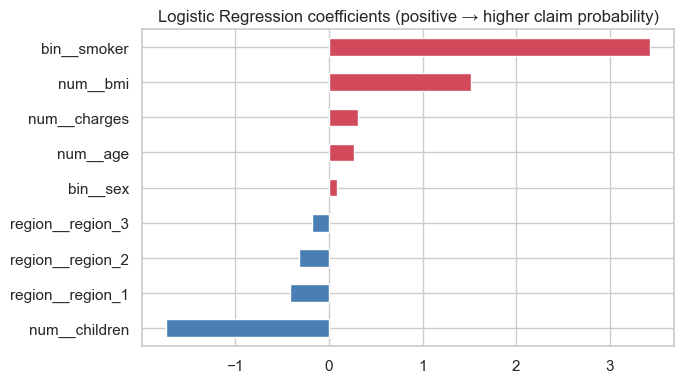

num__children      -1.734
region__region_1   -0.416
region__region_2   -0.315
region__region_3   -0.180
bin__sex            0.087
num__age            0.272
num__charges        0.310
num__bmi            1.520
bin__smoker         3.426
dtype: float64

In [18]:
# Which features drive the prediction? (coefficients on scaled features)
coefs = pd.Series(log_reg.named_steps["model"].coef_[0], index=feature_names).sort_values()
coefs.plot.barh(figsize=(7, 4), color=["#d1495b" if c > 0 else "#4a7fb5" for c in coefs])
plt.title("Logistic Regression coefficients (positive → higher claim probability)")
plt.tight_layout()
plt.show()
coefs.round(3)

### Comparison model — Random Forest

In [19]:
rf = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)),
])
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

results.append(evaluate("Random Forest", y_test, y_pred_rf, y_proba_rf))
summary = pd.DataFrame(results).set_index("model").round(3)
summary

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.862,0.870,0.898,0.884,0.904
Random Forest,0.951,0.944,0.975,0.959,0.992


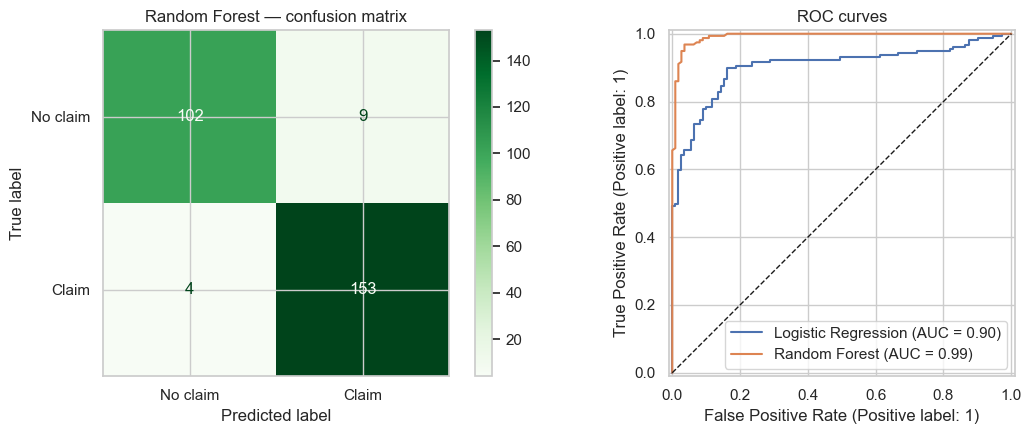

num__bmi            0.363
num__children       0.268
num__charges        0.157
num__age            0.093
bin__smoker         0.085
bin__sex            0.009
region__region_1    0.008
region__region_2    0.008
region__region_3    0.008
dtype: float64

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=["No claim", "Claim"], cmap="Greens", ax=ax[0])
ax[0].set_title("Random Forest — confusion matrix")
RocCurveDisplay.from_predictions(y_test, y_proba_lr, name="Logistic Regression", ax=ax[1])
RocCurveDisplay.from_predictions(y_test, y_proba_rf, name="Random Forest", ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_title("ROC curves")
plt.tight_layout()
plt.show()

importances = pd.Series(rf.named_steps["model"].feature_importances_, index=feature_names).sort_values(ascending=False)
importances.round(3)

In [21]:
# Using the trained model on a new customer
new_customer = pd.DataFrame([{"age": 45, "sex": 1, "bmi": 33.5, "children": 0, "smoker": 0, "region": 2, "charges": 9500.0}])
p = log_reg.predict_proba(new_customer)[0, 1]
print(f"Predicted probability of claim: {p:.2%} -> {'CLAIM' if p >= 0.5 else 'NO CLAIM'}")

Predicted probability of claim: 91.16% -> CLAIM


## Conclusion — Part A

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.862 | 0.870 | 0.898 | 0.884 | 0.904 |
| Random Forest | 0.951 | 0.944 | 0.975 | 0.959 | 0.992 |

*(values from the stratified 80/20 split with `random_state=42`; see the tables above)*

- **Logistic Regression** is a solid, interpretable baseline (ROC-AUC ≈ 0.90). Its coefficients show that **smoking** and **high BMI** strongly increase the probability of a claim, while a higher **number of children** decreases it.
- **Random Forest** performs clearly better on every metric (accuracy ≈ 95%, ROC-AUC ≈ 0.99) because it captures non-linear effects and interactions — e.g. claims depend on BMI and children in a threshold-like way that a linear model cannot represent.
- **Recommended model:** Random Forest for prediction quality; Logistic Regression where a simple, explainable scorecard is needed.
- **Recall** (share of actual claims caught) is high for both models (≈ 0.90–0.98), which matters for an insurer because a missed claim (false negative) means an under-priced, high-risk policy.
- Preprocessing (scaling + one-hot encoding) lives inside a `Pipeline`, so it is fitted on the training data only — no data leakage.

---
## Additional questions (end of the brief, page 5)

The last page of the brief lists five questions that refer to a *healthcare professional*. They do not match Part A (insurance) or Part B (RAG) and appear to belong to a healthcare classification exercise such as diabetes prediction (`diabetes.csv` in the course repo). They are answered here for a **diabetes-prediction model**; the same reasoning applies to the insurance model where noted.

**1. What would the target variable be?**
A binary label indicating whether the patient has diabetes — `Outcome` (1 = diabetic, 0 = not diabetic). For the insurance model in this notebook the equivalent is `insuranceclaim`.

**2. Which evaluation metrics would you consider?**
Accuracy alone is not enough because classes are imbalanced and errors have different costs. Use the **confusion matrix**, **recall (sensitivity)**, **precision**, **specificity**, **F1-score**, and **ROC-AUC / PR-AUC**. Recall is the priority metric, with precision tracked so the model does not flag everyone. The decision threshold can be tuned (e.g. below 0.5) to reach a required recall.

**3. Why could false negatives be particularly important?**
A false negative means a patient who *has* diabetes is told they are fine. They miss early treatment and lifestyle intervention, and the disease can progress to complications (heart disease, kidney damage, neuropathy, vision loss). A false positive usually only leads to a confirmatory blood test (HbA1c / fasting glucose). Because a missed case is far more costly than an extra test, the model should be tuned to minimise false negatives. (In the insurance setting, a false negative is an under-priced high-risk policy.)

**4. How would you explain the prediction to a healthcare professional?**
- Present it as a **risk score / probability** ("this patient has a 72% estimated risk"), not a diagnosis — a screening aid that supports clinical judgement.
- Show the **main contributing factors** for that patient (e.g. high glucose, high BMI, age) using model coefficients or SHAP values, in clinical terms.
- Report the model's **validated performance** (sensitivity, specificity) and the population it was trained on, so the clinician knows how far to trust it.
- Recommend a **next action** (e.g. confirmatory HbA1c test) rather than a final verdict.

**5. What risks should be considered before deploying the model?**
- **Bias and fairness** — training data may under-represent some groups (e.g. `diabetes.csv` is from a single population of Pima women), so performance may not generalise.
- **Data quality** — physiologically impossible zeros (glucose, BMI, blood pressure = 0) treated as real values; missing data; measurement differences between clinics.
- **Data drift** — patient populations and measurement practices change over time; the model needs monitoring and periodic retraining.
- **Over-reliance / automation bias** — clinicians must remain the decision-makers; human-in-the-loop review is required.
- **Privacy and regulation** — patient data must be handled under HIPAA/GDPR-type rules; medical decision-support software may need regulatory approval.
- **Explainability and accountability** — clear documentation of limitations, intended use and who is responsible for decisions.
- **Threshold choice** — the cut-off must reflect the clinical cost of false negatives vs false positives and be validated prospectively before real use.